### Importando Bibliotecas

In [2]:
import numpy as np
import pandas as pd

from sklearn import datasets as ds
from sklearn import tree as tr
from sklearn import metrics as mt
from sklearn import model_selection as ms

from matplotlib import pyplot as plt

### Criando Dados Sintéticos Para o Exercício

In [3]:
#aqui criamos dados sintéticos para podermos realizarmos o exercício
n_samples = 20000 #numero de linhas
n_features = 2 #numero de colunas
n_informative = 2 #numero de colunas relevantes
n_redundant = 0 #numero de features redundantes, no caso, nenhuma
random_state = 0 #valor randômmico de aleatoriedade, poderia ser qualquer número
#x, y = x é o dataset, linhas e colunas, x.shape retorna (2000, 2) y é o valor da coluna preditiva, classificação das classes, retorna y.shape [0, 1, 1, 1, 0, 1, 0, 0, ...]

#crianto os dados para treinamento
x, y = ds.make_classification (
    n_samples = n_samples,
    n_features = n_features,
    n_informative = n_informative,
    n_redundant = n_redundant,
    random_state = random_state
)

# 1.0 Previsão apenas treinando com dados de treino

### aqui ele pega o dataset, separa em 80% treino e 20% teste, mas ele treina com o dataset de treino e coloca em produção o mesmo dataset, dando 100% de acc

In [4]:
#Dados para produção. Ele separa 20% pra prod mas aqui não é utilizado como treino, apenas para produçao final
#20.000 linhas totais: 16.000 linhas dataset de treino e 4000 dataset de produção
x, x_prod, y, y_prod = ms.train_test_split(x, y, test_size=0.2)

#Modelo treinado e validado com dataset de treinamento
#parametro de 38 no modelo de forma aleatoria
model = tr.DecisionTreeClassifier(max_depth=38)
model.fit(x, y)

#previsão sobre os dados de treinamento, ou seja, usou o dado de treinamento para medir a acurácia, o que da 100% por ser o mesmo dado de treino
y_hat = model.predict(x)
#medindo acurácia, y_hat(previsao) - y(correto)
acc = mt.accuracy_score(y, y_hat)

print(f'Accuracy Over Training: {acc}')

Accuracy Over Training: 1.0


# 1.1 Aplicando em produção com previsão apenas treinado com os dados de treino e produção dados de teste

### já aqui ele usa os 20% de dataset que ainda nao tinha sido visto pelo modelo, para produção, exclusivamente separado, sem concatenar, fazendo acc abaixar bem

In [5]:
#Publicando o modelo em produção
#previsao sobre os dados de teste agora, dados que não foram vistos ainda pelo modelo, que foi treinado com os dados de treino apenas
y_hat_prod = model.predict(x_prod)
acc_prod = mt.accuracy_score(y_prod, y_hat_prod)

print(f'Accuracy Over Production: {acc_prod}')

Accuracy Over Production: 0.84925


# 2.0 Estratégia Treino-Teste

### aqui ele também separa os dados em 80-20, treino e teste. Ele faz o treino com o dataset de treino, achando o model fit com ele igual no caso 1.0 também. Porém depois ele faz a previsão com com os dados test, achando a acurácia do teste, separadamente do dataset treino, igualmente no 1.1

In [6]:
#separando os dados entre Treino e Teste, teste em 20% e pegando aleatoriamente com random_state
x_train, x_test, y_train, y_test = ms.train_test_split(x, y, test_size=0.2, random_state=random_state)
#20% de 16.000 que é x, y = 3200 linhas para x_test e y_test, ficando x_train e y_train com 12.800 linhas

#modelo treinado e validado com dataset de treino
model = tr.DecisionTreeClassifier(max_depth=58)
model.fit(x_train, y_train)

#previsao sobre os dados de teste
y_hat_test = model.predict(x_test)
acc_test = mt.accuracy_score(y_test, y_hat_test)

#agora aqui, treinamos com o dado de treino e testamos com dados que nunca foram vistos, o de test

print(f'Accuracy Over Test {acc_test}')

Accuracy Over Test 0.8490625


# 2.1 Como achar o melhor parâmetro

### na busca para melhor a acuracia do modelo, aqui buscamos encontrar o melhor parâmetro para fazer o modelo encontrar o melhor fit fazendo os testes com os dados ainda não vistos, o dataset de teste, que é separado nos 20%.

### com o melhor parâmetro, radamos o modelo em produção, juntando os dados (treino+teste), achando o model.fit e o predict da produção.

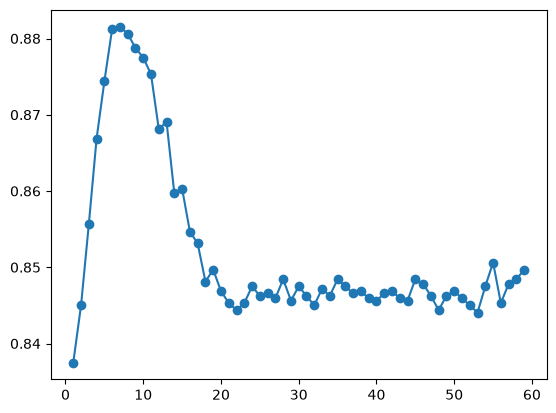

In [7]:
values = [i for i in range(1, 60)]
test_scores = []

for i in values:
    #para cada valor de 1 a 59 ele vai testar o parametro e definir o melhor model.fit
    model = tr.DecisionTreeClassifier(max_depth=i)
    model.fit(x_train, y_train)

    #prevendo com parametro vai se dar melhor
    y_hat_test = model.predict(x_test)
    acc_test = mt.accuracy_score(y_test, y_hat_test)

    #adiciona/guarda na lista de test_scores os valores testados de 1, 59
    test_scores.append(acc_test)

#plotando os valores, para vermos qual é o melhor max_depth, ou melhor, o melhor parâmetro a ser utilizado
plt.plot(values, test_scores, '-o', label='test')

In [8]:
#pelo gráfico acima, o valor do melhor parâmetro é 9, agora a gente vai utilizar ele para rodar a produção
#publicando o modelo em produção com x_prod e y_prod no qual não foi juntado ao (x_train e x_test), (y_train y_test)
#modelo treinado com dataset de treino e validado com dataset de teste
model_last = tr.DecisionTreeClassifier(max_depth=9)
model_last.fit(
    np.concatenate((x_train, x_test)),
    np.concatenate((y_train, y_test))
)

#previsão sobre os dados de produção
y_hat_prod = model_last.predict(x_prod)
acc_prod = mt.accuracy_score(y_prod, y_hat_prod)

print(f'Accuracy Ober Producion: {acc_prod}')

Accuracy Ober Producion: 0.88025


# 3.0 Estratégia Treino-Validation-Teste (Holdout Completo)

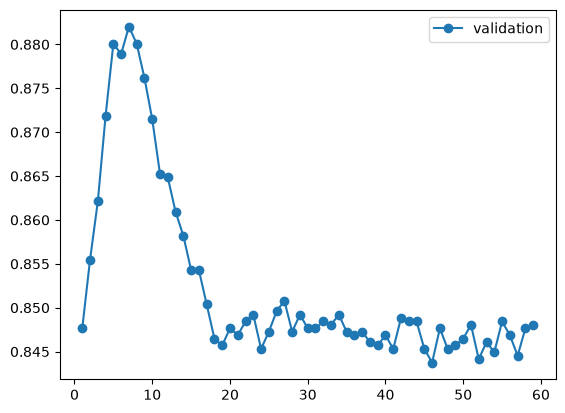

In [9]:
#separando agora em trein-validação-teste-produção
#como o restante já existe, agrora criamos o validação (val)
x_train, x_val, y_train, y_val = ms.train_test_split(x_train, y_train, test_size=0.2)
#x e y_train antes: 12800, pós split: 10240 e x e y_val: 2560

#vamos achar o melhor parâmetro utilizando o dataset de validação
values = [i for i in range( 1, 60 )]
validation_scores = []

for i in values:
    model_3 = tr.DecisionTreeClassifier(max_depth=i)
    model_3.fit(x_train, y_train)

    #previsão com o validação
    y_hat_val = model_3.predict(x_val)
    acc_val = mt.accuracy_score(y_val, y_hat_val)

    #guarda os valores em test_score
    validation_scores.append(acc_val)

#plotando esses novos dados para ver o melhor parâmetro
plt.plot(values, validation_scores, '-o', label='validation')
plt.legend()
plt.show()

In [10]:
#previsão sobre os dados de validação
y_hat_val = model_3.predict(x_val)
acc_val = mt.accuracy_score(y_val, y_hat_val)

print(f'Accuracy Over Validation: {acc_val}')

#com o melhor parâmetro com dado de validação, voltamos e utilizamos esse parâmetro para treinar os dados todos
model_last = tr.DecisionTreeClassifier(max_depth=5)
model_last.fit(
    np.concatenate((x_train, x_val)),
    np.concatenate((y_train, y_val))
)

#previsao sobre os dados de test
y_hat_test = model_last.predict(x_test)
acc_test = mt.accuracy_score(y_test, y_hat_test)

print(f'Accuracy Over Test: {acc_test}')

#previsão sobre os dados de produção com essses parâmetros definidos:
y_hat_prod = model_last.predict(x_prod)
acc_prod = mt.accuracy_score(y_prod, y_hat_prod)

print(f'Accuracy Over Production:{acc_prod}')

Accuracy Over Validation: 0.848046875
Accuracy Over Test: 0.874375
Accuracy Over Production:0.88
